# SPEI Drought Analysis: Zimbabwe (national) and Bulawayo (case study), 1981-2024

This notebook answers **Standardized Precipitation Evapotranspiration Index (SPEI)** of the Drought Monitoring Indices assignment.

| Brief says | What this notebook does |
|---|---|
| **Objective:** evaluate the climatic water balance (precipitation and PET) and the compounding impact of **temperature increases** on drought severity | Computes SPEI, then tests how temperature and PET change affect drought severity (Section 10) |
| **Data:** precipitation combined with temperature datasets (CRU, ERA5) used to **calculate PET** via Thornthwaite or FAO Penman-Monteith | Precipitation from TerraClimate; temperature from **ERA5-Land**; PET **calculated here with Thornthwaite**; TerraClimate's FAO Penman-Monteith PET used as a second method |
| **Method:** D = P - PET aggregated over multi-month scales, fitted to a **log-logistic** distribution | Scales of 1, 3, 6 and 12 months; log-logistic fit per calendar month (Sections 5-6) |
| **Narrative:** under higher temperatures PET rises and SPEI falls below SPI in dry spells | Tested directly with two PET methods (Sections 7-10) |
| **Visual:** SPEI vs SPI comparison | Figure 2 (and Figure 3 for the temperature effect) |

**Study areas:** Zimbabwe (national) and Bulawayo (a semi-arid city in the south-west, as a local case study).

**Before you run:** you need a Google Earth Engine account and a Google Cloud project ID
(https://code.earthengine.google.com/register, choose noncommercial/education). Put the project ID in the
parameters cell. Run the cells from top to bottom.

## 1. Install and import
Installs `geemap` (helper for Earth Engine) and imports the libraries. `numpy`/`pandas` handle the data,
`scipy` fits the probability distributions, `matplotlib` draws the figures.

In [1]:
!pip install -q geemap

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gamma as gamma_fn
import warnings
warnings.filterwarnings('ignore')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 45.1 MB/s eta 0:00:00


## 2. Authenticate with Google Earth Engine
A pop-up asks you to sign in with the Google account that has Earth Engine access. Replace the project ID.

In [2]:
PROJECT_ID = 'YOUR_GEE_PROJECT_ID'

ee.Authenticate()
ee.Initialize(project=PROJECT_ID)
print('Earth Engine ready')

Earth Engine ready


## 3. Parameters and study areas
* **Period:** Jan 1981 to Dec 2024 (44 years; SPEI needs 30+ years to fit the distribution well).
* **Time scales:** 1, 3, 6, 12 months. SPEI-3 reflects seasonal/agricultural drought, SPEI-12 hydrological drought.
* **Zimbabwe boundary:** from the USDOS LSIB international boundaries dataset.
* **Bulawayo:** a 10 km circle around the city centre (about 28.58 E, 20.15 S).
* **Datasets:**
  * precipitation (`pr`) and Penman-Monteith PET (`pet`): TerraClimate, about 4.6 km, monthly;
  * air temperature (`temperature_2m`): ERA5-Land monthly, about 11 km.

In [3]:
START, END = '1981-01-01', '2025-01-01'     # END is exclusive
SCALES = [1, 3, 6, 12]

ZIMBABWE = (ee.FeatureCollection('USDOS/LSIB_SIMPLE/2017')
            .filter(ee.Filter.eq('country_na', 'Zimbabwe')).geometry())
BULAWAYO = ee.Geometry.Point([28.58, -20.15]).buffer(10000)
AREAS = {'Zimbabwe': ZIMBABWE, 'Bulawayo': BULAWAYO}

tc = (ee.ImageCollection('IDAHO_EPSCOR/TERRACLIMATE')
      .filterDate(START, END).select(['pr', 'pet']))
era = (ee.ImageCollection('ECMWF/ERA5_LAND/MONTHLY_AGGR')
       .filterDate(START, END).select('temperature_2m'))
print('TerraClimate months:', tc.size().getInfo(), '| ERA5-Land months:', era.size().getInfo())   # expect 528 each

TerraClimate months: 528 | ERA5-Land months: 528


## 4. Get the data
**4a. Precipitation and Penman-Monteith PET (TerraClimate).** For every month, Earth Engine averages `pr` and `pet` over each study area
(`reduceRegion`) and we pull the result into a table (mm/month). TerraClimate stores PET with a scale factor of 0.1; the code checks the
magnitude and corrects it if needed. TerraClimate's `pet` is a FAO-56 style Penman-Monteith reference evapotranspiration, so it is our
"Penman-Monteith" method.

In [4]:
def extract_series(geom):
    def per_image(img):
        vals = img.reduceRegion(reducer=ee.Reducer.mean(), geometry=geom,
                                scale=4638.3, maxPixels=1e9, bestEffort=True)
        return ee.Feature(None, vals).set('date', img.date().format('YYYY-MM-dd'))
    feats = ee.FeatureCollection(tc.map(per_image)).getInfo()['features']
    df = pd.DataFrame([f['properties'] for f in feats])
    df['date'] = pd.to_datetime(df['date'])
    return (df.set_index('date').sort_index()
              .rename(columns={'pr': 'P', 'pet': 'PET'})[['P', 'PET']])

raw = {name: extract_series(g) for name, g in AREAS.items()}

# TerraClimate PET is stored x10. Zimbabwe's PET is roughly 100-200 mm/month, so raw values >300 mean unscaled.
PET_SCALE = 0.1 if raw['Zimbabwe']['PET'].mean() > 300 else 1.0
for name in raw:
    raw[name]['PET'] = raw[name]['PET'] * PET_SCALE

for name, d in raw.items():
    print(f"{name}: mean annual P = {d.P.resample('YS').sum().mean():.0f} mm, "
          f"mean annual Penman-Monteith PET = {d.PET.resample('YS').sum().mean():.0f} mm")
# Sanity check: Zimbabwe should be roughly 600-800 mm rain and 1500-1900 mm PET per year.

Zimbabwe: mean annual P = 636 mm, mean annual Penman-Monteith PET = 1581 mm
Bulawayo: mean annual P = 572 mm, mean annual Penman-Monteith PET = 1607 mm


**4b. Air temperature (ERA5-Land).** Same idea: monthly 2 m air temperature averaged over each area, converted from Kelvin to degrees Celsius.
This is the temperature dataset the brief asks for (ERA5), and it is what we use to **calculate PET ourselves**.

In [5]:
def extract_temp(geom):
    def per_image(img):
        vals = img.reduceRegion(reducer=ee.Reducer.mean(), geometry=geom,
                                scale=11132, maxPixels=1e9, bestEffort=True)
        return ee.Feature(None, vals).set('date', img.date().format('YYYY-MM-dd'))
    feats = ee.FeatureCollection(era.map(per_image)).getInfo()['features']
    df = pd.DataFrame([f['properties'] for f in feats])
    df['date'] = pd.to_datetime(df['date'])
    return df.set_index('date').sort_index()['temperature_2m'] - 273.15

temps = {name: extract_temp(g) for name, g in AREAS.items()}
for name, t in temps.items():
    print(f'{name}: {len(t)} months, mean temperature = {t.mean():.1f} C')

Zimbabwe: 528 months, mean temperature = 21.2 C
Bulawayo: 528 months, mean temperature = 19.2 C


**4c. Calculate PET with the Thornthwaite method.** Thornthwaite estimates PET from air temperature alone:

`PET = 16 x (10 T / I)^a x (N / 12) x (days / 30)`

* `T` = monthly mean temperature (months at or below 0 C get zero PET);
* `I` = annual heat index, the sum over the 12 calendar months of `(T / 5)^1.514` using long-term mean temperatures;
* `a` = a polynomial of `I`;
* `N` = day length in hours, from latitude and time of year;
* `days` = number of days in the month.

Because it uses temperature only, Thornthwaite is the simplest way to see the **temperature effect** on drought.
It is also known to react more strongly to warming than Penman-Monteith (which also uses wind, humidity and radiation),
so we keep TerraClimate's Penman-Monteith PET as a second method and compare the two.

In [6]:
LATS = {'Zimbabwe': -19.0, 'Bulawayo': -20.15}      # approximate latitude of each area

def thornthwaite(T, lat_deg):
    """Monthly Thornthwaite PET (mm) from a monthly-mean temperature series (deg C, month-start index)."""
    Tc = T.clip(lower=0)
    clim = Tc.groupby(Tc.index.month).mean()                 # long-term mean temperature of each calendar month
    I = ((clim / 5.0) ** 1.514).sum()                        # annual heat index
    a = 6.75e-7 * I**3 - 7.71e-5 * I**2 + 1.792e-2 * I + 0.49239
    mid = T.index + pd.Timedelta(days=14)                    # mid-month day of year
    doy = np.asarray(mid.dayofyear, float)
    decl = 0.409 * np.sin(2 * np.pi / 365 * doy - 1.39)      # solar declination (radians)
    phi = np.radians(lat_deg)
    ws = np.arccos(np.clip(-np.tan(phi) * np.tan(decl), -1, 1))
    N = 24 / np.pi * ws                                      # day length in hours
    days = np.asarray(T.index.days_in_month, float)
    pet = 16.0 * (N / 12.0) * (days / 30.0) * (10.0 * Tc.values / I) ** a
    pet = np.where(Tc.values > 0, pet, 0.0)
    return pd.Series(pet, index=T.index, name='PET')

data = {}
for name in AREAS:
    d = raw[name].rename(columns={'PET': 'PET_pm'}).copy()    # PET_pm = Penman-Monteith (TerraClimate)
    d['T'] = temps[name].reindex(d.index)
    d['PET'] = thornthwaite(d['T'], LATS[name])               # PET = Thornthwaite (calculated here)
    data[name] = d

for name, d in data.items():
    ann = d[['PET', 'PET_pm']].resample('YS').sum().mean()
    print(f"{name}: mean annual PET: Thornthwaite = {ann['PET']:.0f} mm, Penman-Monteith = {ann['PET_pm']:.0f} mm")
print('(The two methods can differ in level; SPEI standardizes each, so what matters is variability and trend.)')

Zimbabwe: mean annual PET: Thornthwaite = 1021 mm, Penman-Monteith = 1581 mm
Bulawayo: mean annual PET: Thornthwaite = 891 mm, Penman-Monteith = 1607 mm
(The two methods can differ in level; SPEI standardizes each, so what matters is variability and trend.)


## 5. The SPEI and SPI functions (the core of the analysis)

**Steps inside `calc_index`:**
1. Add the monthly series over a rolling window of `k` months (the time scale).
2. Do the next steps **separately for each calendar month** (all Januaries together, all Februaries together...) so the seasonal cycle is removed.
3. **SPEI:** fit a 3-parameter **log-logistic** distribution to `D = P - PET` using unbiased probability-weighted moments (the method of Vicente-Serrano et al. 2010).
   **SPI:** fit a **Gamma** distribution to precipitation, handling months with zero rain separately.
4. Convert each value to a cumulative probability, then to a standard-normal z-score (`norm.ppf`). That z-score is the index (mean 0, SD 1).
5. Values are capped at +/-3 to avoid extreme tails from short records.
6. If a log-logistic fit is not valid for some calendar month (it can happen in very dry months), the code falls back to a normal distribution so there are no gaps.

In [7]:
def fit_loglogistic(x):
    """3-parameter log-logistic via unbiased PWM. Returns (alpha, beta, gamma_loc) or None."""
    x = np.sort(np.asarray(x, float))
    x = x[~np.isnan(x)]
    n = len(x)
    if n < 10:
        return None
    i = np.arange(1, n + 1)
    w0 = x.mean()
    w1 = np.sum((n - i) / (n - 1) * x) / n
    w2 = np.sum((n - i) * (n - i - 1) / ((n - 1) * (n - 2)) * x) / n
    denom = 6 * w1 - w0 - 6 * w2
    if denom == 0:
        return None
    beta = (2 * w1 - w0) / denom
    if not np.isfinite(beta) or beta <= 1:
        return None
    g1, g2 = gamma_fn(1 + 1 / beta), gamma_fn(1 - 1 / beta)
    alpha = (w0 - 2 * w1) * beta / (g1 * g2)
    loc = w0 - alpha * g1 * g2
    return alpha, beta, loc


def loglogistic_cdf(x, params):
    a, b, c = params
    d = np.asarray(x, float) - c
    with np.errstate(all='ignore'):
        F = np.where(d > 0, 1.0 / (1.0 + (a / d) ** b), 1e-6)
    return F


def to_z(F):
    return np.clip(stats.norm.ppf(np.clip(F, 1e-6, 1 - 1e-6)), -3, 3)


def calc_index(series, k, kind):
    """kind = 'spei' (series is D = P - PET) or 'spi' (series is P)."""
    agg = series.rolling(k).sum()
    out = pd.Series(np.nan, index=agg.index)
    for m in range(1, 13):
        sel = agg[agg.index.month == m].dropna()
        if len(sel) < 20:
            continue
        v = sel.values
        if kind == 'spei':
            p = fit_loglogistic(v)
            if p is None:
                # fallback when the log-logistic fit is not valid (e.g. very dry months): normal distribution
                F = stats.norm.cdf(v, loc=v.mean(), scale=v.std(ddof=1))
            else:
                F = loglogistic_cdf(v, p)
        else:
            pos = v[v > 0]
            if len(pos) < 10:
                continue
            q = 1 - len(pos) / len(v)                      # probability of zero rainfall
            a, _, scale = stats.gamma.fit(pos, floc=0)
            F = q + (1 - q) * stats.gamma.cdf(v, a, loc=0, scale=scale)
        out.loc[sel.index] = to_z(F)
    return out


def classify(z):
    if np.isnan(z): return 'n/a'
    if z <= -2:   return 'Extreme drought'
    if z <= -1.5: return 'Severe drought'
    if z <= -1:   return 'Moderate drought'
    if z < 1:     return 'Near normal'
    return 'Wet'

## 6. Compute the indices for both areas
For each area we compute the water balance twice and the standardized indices three ways:
* `SPEI{k}`: from `D = P - PET` with **Thornthwaite PET** (our main method, calculated from ERA5-Land temperature);
* `SPEIpm{k}`: from `D = P - PET` with **Penman-Monteith PET** (TerraClimate), for comparison;
* `SPI{k}`: from precipitation only.

The printout checks that each SPEI series has mean close to 0 and standard deviation close to 1,
which is the quick test that the standardization worked.

In [8]:
res = {}
for name, d in data.items():
    d = d.copy()
    d['D'] = d['P'] - d['PET']
    d['D_pm'] = d['P'] - d['PET_pm']
    for k in SCALES:
        d[f'SPEI{k}'] = calc_index(d['D'], k, 'spei')
        d[f'SPEIpm{k}'] = calc_index(d['D_pm'], k, 'spei')
        d[f'SPI{k}'] = calc_index(d['P'], k, 'spi')
    res[name] = d

for name, d in res.items():
    print(f'\n{name}: validation (mean should be ~0, SD ~1)')
    for k in SCALES:
        s = d[f'SPEI{k}'].dropna()
        print(f'  SPEI-{k:<2d} (Thornthwaite) mean={s.mean():+.2f}  sd={s.std():.2f}  n={len(s)}')


Zimbabwe: validation (mean should be ~0, SD ~1)
  SPEI-1  (Thornthwaite) mean=+0.01  sd=0.98  n=528
  SPEI-3  (Thornthwaite) mean=+0.00  sd=0.99  n=526
  SPEI-6  (Thornthwaite) mean=+0.00  sd=0.99  n=523
  SPEI-12 (Thornthwaite) mean=-0.00  sd=0.99  n=517

Bulawayo: validation (mean should be ~0, SD ~1)
  SPEI-1  (Thornthwaite) mean=+0.01  sd=0.99  n=528
  SPEI-3  (Thornthwaite) mean=+0.00  sd=0.98  n=526
  SPEI-6  (Thornthwaite) mean=+0.00  sd=0.98  n=523
  SPEI-12 (Thornthwaite) mean=+0.00  sd=0.98  n=517


## 7. Drought summary tables
Counts how often each area was in drought under SPI, SPEI (Thornthwaite) and SPEI (Penman-Monteith), lists the 5 worst months by SPEI-12,
and compares how deep each index went in the main drought events. Use these numbers on your Conclusion slide.

In [9]:
for name, d in res.items():
    print(f'\n=== {name} ===')
    print('Months in drought, 12-month scale:')
    for lab, col in [('SPI-12', 'SPI12'), ('SPEI-12 (Thornthwaite)', 'SPEI12'), ('SPEI-12 (Penman-Monteith)', 'SPEIpm12')]:
        s = d[col].dropna()
        print(f'  {lab:<27s} < -1.0: {(s < -1).sum():3d} of {len(s)} ({100*(s < -1).mean():.0f}%)   < -1.5: {(s < -1.5).sum():3d}')
    s12 = d['SPEI12'].dropna()
    print('Five worst months by SPEI-12 (Thornthwaite):')
    for dt, v in s12.nsmallest(5).items():
        print(f'  {dt:%b %Y}: SPEI-12 = {v:.2f}  ({classify(v)})')
    print('Deepest 12-month value in each major drought year:')
    for yr in [1992, 2016, 2024]:
        m = d[d.index.year == yr]
        print(f"  {yr}: SPI-12 = {m['SPI12'].min():.2f} | SPEI-12 Thornthwaite = {m['SPEI12'].min():.2f} | SPEI-12 Penman-Monteith = {m['SPEIpm12'].min():.2f}")


=== Zimbabwe ===
Months in drought, 12-month scale:
  SPI-12                      < -1.0:  94 of 517 (18%)   < -1.5:  44
  SPEI-12 (Thornthwaite)      < -1.0:  82 of 517 (16%)   < -1.5:  43
  SPEI-12 (Penman-Monteith)   < -1.0:  90 of 517 (17%)   < -1.5:  44
Five worst months by SPEI-12 (Thornthwaite):
  Feb 2016: SPEI-12 = -2.43  (Extreme drought)
  Apr 2016: SPEI-12 = -2.35  (Extreme drought)
  Dec 2024: SPEI-12 = -2.33  (Extreme drought)
  Jan 2016: SPEI-12 = -2.27  (Extreme drought)
  Mar 2016: SPEI-12 = -2.25  (Extreme drought)
Deepest 12-month value in each major drought year:
  1992: SPI-12 = -2.39 | SPEI-12 Thornthwaite = -2.22 | SPEI-12 Penman-Monteith = -2.09
  2016: SPI-12 = -2.30 | SPEI-12 Thornthwaite = -2.43 | SPEI-12 Penman-Monteith = -2.08
  2024: SPI-12 = -2.30 | SPEI-12 Thornthwaite = -2.33 | SPEI-12 Penman-Monteith = -2.38

=== Bulawayo ===
Months in drought, 12-month scale:
  SPI-12                      < -1.0:  69 of 517 (13%)   < -1.5:  41
  SPEI-12 (Thornthwaite

## 8. Figure 1: SPEI time series (Zimbabwe)
Red bars = drier than normal, blue = wetter. Dotted/dashed/solid lines mark the moderate (-1), severe (-1.5)
and extreme (-2) drought thresholds. SPEI-3 shows seasonal droughts (a failed rainy season),
SPEI-12 shows the long, persistent droughts that affect dams and groundwater. (Thornthwaite-based SPEI.)

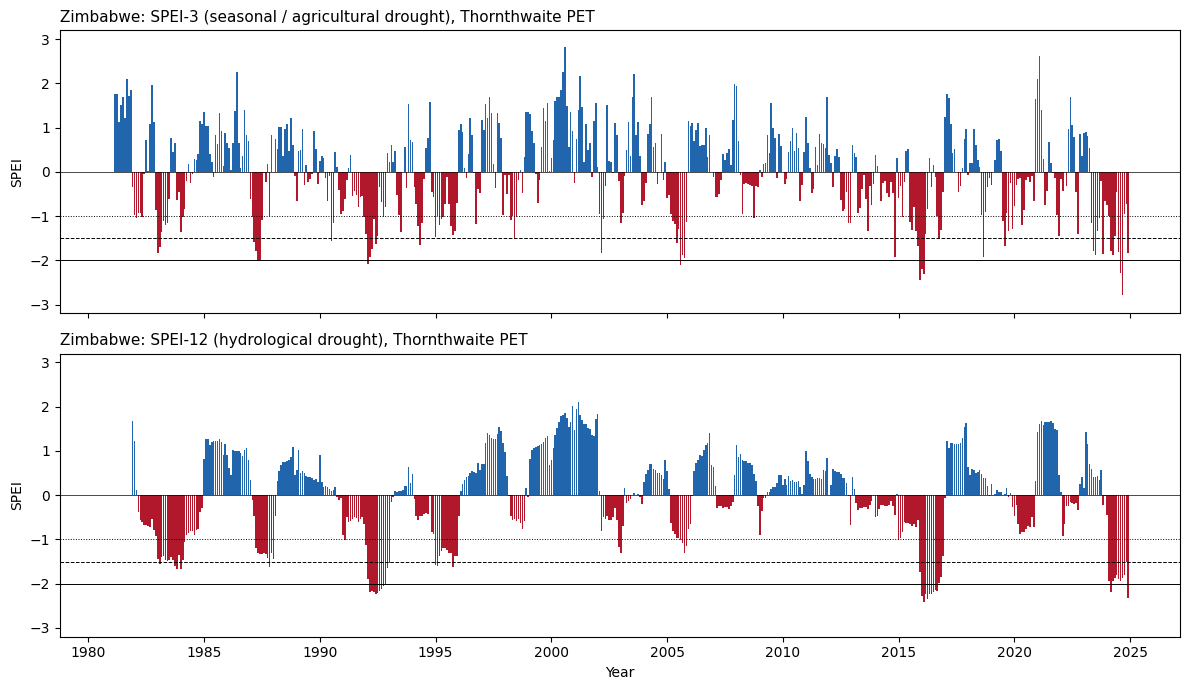

In [10]:
def bar_series(ax, s, title):
    ax.bar(s.index, s.where(s >= 0, 0), width=25, color='#2166ac')
    ax.bar(s.index, s.where(s < 0, 0), width=25, color='#b2182b')
    for y, ls in [(-1, ':'), (-1.5, '--'), (-2, '-')]:
        ax.axhline(y, color='k', ls=ls, lw=0.7)
    ax.axhline(0, color='k', lw=0.5)
    ax.set_ylim(-3.2, 3.2)
    ax.set_ylabel('SPEI')
    ax.set_title(title, loc='left', fontsize=11)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
bar_series(axes[0], res['Zimbabwe']['SPEI3'], 'Zimbabwe: SPEI-3 (seasonal / agricultural drought), Thornthwaite PET')
bar_series(axes[1], res['Zimbabwe']['SPEI12'], 'Zimbabwe: SPEI-12 (hydrological drought), Thornthwaite PET')
axes[1].set_xlabel('Year')
plt.tight_layout()
plt.savefig('fig1_spei_timeseries_zimbabwe.png', dpi=200)
plt.show()

## 9. Figure 2: SPEI vs SPI (the comparison the brief asks for)
SPI uses rainfall only; SPEI adds evaporative demand. The brief's claim is that during dry spells SPEI dips **lower** than SPI because warm,
dry conditions raise PET. Top two panels: SPEI-3 (Thornthwaite) against SPI-3 for Zimbabwe and Bulawayo. Bottom panel: the same at the 12-month scale for Zimbabwe.

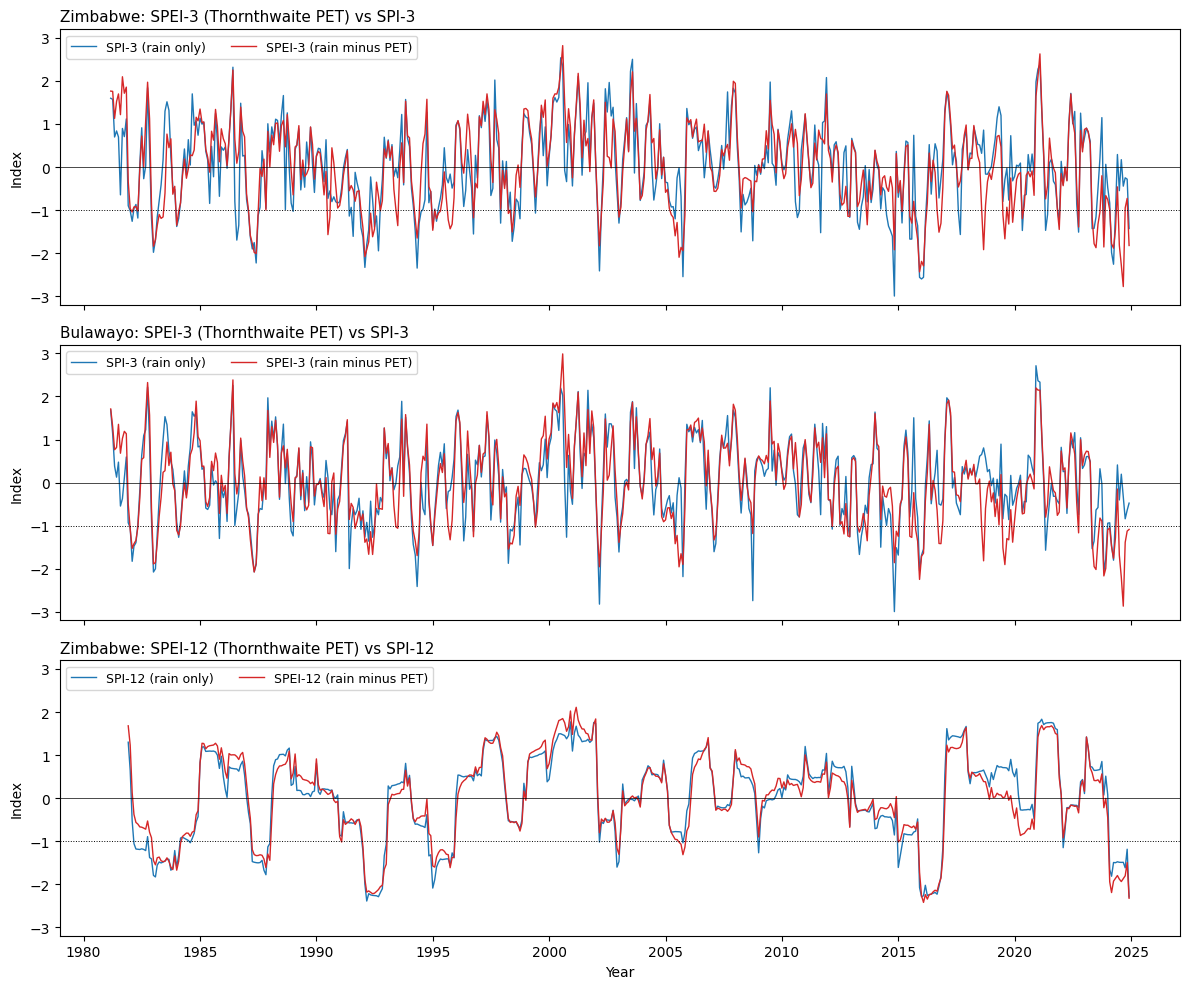

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
panels = [('Zimbabwe', 3), ('Bulawayo', 3), ('Zimbabwe', 12)]
for ax, (name, k) in zip(axes, panels):
    d = res[name]
    ax.plot(d.index, d[f'SPI{k}'], color='tab:blue', lw=1.0, label=f'SPI-{k} (rain only)')
    ax.plot(d.index, d[f'SPEI{k}'], color='tab:red', lw=1.0, label=f'SPEI-{k} (rain minus PET)')
    ax.axhline(-1, color='k', ls=':', lw=0.7)
    ax.axhline(0, color='k', lw=0.5)
    ax.set_ylim(-3.2, 3.2)
    ax.set_ylabel('Index')
    ax.set_title(f'{name}: SPEI-{k} (Thornthwaite PET) vs SPI-{k}', loc='left', fontsize=11)
    ax.legend(loc='upper left', ncol=2, fontsize=9)
axes[-1].set_xlabel('Year')
plt.tight_layout()
plt.savefig('fig2_spei_vs_spi.png', dpi=200)
plt.show()

## 10. Quantifying the temperature effect (the objective of the brief)
This section tests the brief's narrative with numbers instead of eyeballing the plot. For each area it reports:
1. **Trends** (per decade) in temperature and in PET from both methods. Is the climate warming, and does PET rise with it?
2. **SPEI minus SPI in dry months** (SPI-3 below -1). A **negative** value means SPEI shows the drought as more severe than SPI, as the brief predicts.
3. **Regression of (SPEI-3 minus SPI-3) on the 3-month temperature anomaly.** A **negative slope** means that when it is warmer than normal,
   SPEI falls further below SPI: the compounding effect of temperature on drought severity.
4. **Share of months in drought by period**, for SPI and both SPEI versions: does SPEI show more drought than SPI in recent, warmer decades?

Figure 3 shows annual PET from both methods and the regression for Zimbabwe.


=== Zimbabwe ===
1) Trends per decade:
   Air temperature        +0.13 C  (p = 0.054)
   PET Thornthwaite       +15.09 mm  (p = 0.050)
   PET Penman-Monteith    +1.91 mm  (p = 0.770)
2) Dry months (SPI-3 < -1), n = 84: mean SPEI-3 minus SPI-3
   Thornthwaite PET:    +0.35
   Penman-Monteith PET: +0.24
3) Slope of (SPEI-3 minus SPI-3) against 3-month temperature anomaly:
   Thornthwaite     slope = -0.41 per C, r = -0.53, p = 0.000
   Penman-Monteith  slope = -0.20 per C, r = -0.33, p = 0.000
4) Share of months with index < -1, by period:
   period  SPI-3 %  SPEI-3 Thornthwaite %  SPEI-3 Penman-Monteith %
1981-1990     15.0                   16.0                      18.0
1991-2000     19.0                   20.0                      19.0
2001-2010      8.0                   10.0                      11.0
2011-2024     20.0                   21.0                      21.0

=== Bulawayo ===
1) Trends per decade:
   Air temperature        +0.12 C  (p = 0.114)
   PET Thornthwaite       +1

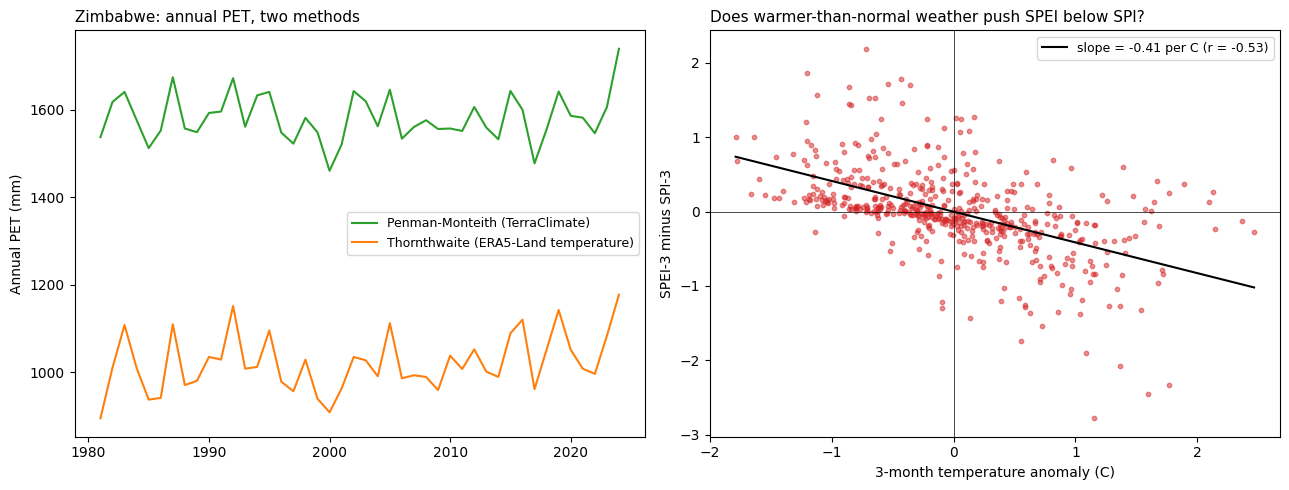

In [12]:
PERIODS = [(1981, 1990), (1991, 2000), (2001, 2010), (2011, 2024)]

def share(x):
    x = x.dropna()
    return 100 * (x < -1).mean()

for name, d in res.items():
    print(f'\n=== {name} ===')
    ann = d[['T', 'PET', 'PET_pm']].resample('YS').agg({'T': 'mean', 'PET': 'sum', 'PET_pm': 'sum'})
    ann = ann[ann.index.year <= 2024]
    print('1) Trends per decade:')
    for col, lab, unit in [('T', 'Air temperature', 'C'), ('PET', 'PET Thornthwaite', 'mm'), ('PET_pm', 'PET Penman-Monteith', 'mm')]:
        r = stats.linregress(ann.index.year, ann[col])
        print(f'   {lab:<22s} {r.slope * 10:+.2f} {unit}  (p = {r.pvalue:.3f})')

    x = d.dropna(subset=['SPEI3', 'SPEIpm3', 'SPI3'])
    dry = x[x['SPI3'] < -1]
    print(f'2) Dry months (SPI-3 < -1), n = {len(dry)}: mean SPEI-3 minus SPI-3')
    print(f"   Thornthwaite PET:    {np.mean(dry['SPEI3'] - dry['SPI3']):+.2f}")
    print(f"   Penman-Monteith PET: {np.mean(dry['SPEIpm3'] - dry['SPI3']):+.2f}")

    Tan = d['T'] - d['T'].groupby(d.index.month).transform('mean')      # temperature anomaly
    Tan3 = Tan.rolling(3).mean()
    print('3) Slope of (SPEI-3 minus SPI-3) against 3-month temperature anomaly:')
    for lab, col in [('Thornthwaite', 'SPEI3'), ('Penman-Monteith', 'SPEIpm3')]:
        z = pd.concat([Tan3.rename('x'), (d[col] - d['SPI3']).rename('y')], axis=1).dropna()
        r = stats.linregress(z['x'], z['y'])
        print(f'   {lab:<16s} slope = {r.slope:+.2f} per C, r = {r.rvalue:+.2f}, p = {r.pvalue:.3f}')

    rows = []
    for a, b in PERIODS:
        s = d[(d.index.year >= a) & (d.index.year <= b)]
        rows.append({'period': f'{a}-{b}', 'SPI-3 %': share(s['SPI3']),
                     'SPEI-3 Thornthwaite %': share(s['SPEI3']), 'SPEI-3 Penman-Monteith %': share(s['SPEIpm3'])})
    print('4) Share of months with index < -1, by period:')
    print(pd.DataFrame(rows).round(0).to_string(index=False))

print('\nHow to read this: negative SPEI-minus-SPI values and negative slopes support the brief (warming deepens drought).')
print('Values near zero or positive mean drought in this dataset is driven mainly by rainfall.')

z = res['Zimbabwe']
Tan3 = (z['T'] - z['T'].groupby(z.index.month).transform('mean')).rolling(3).mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ann = z[['PET', 'PET_pm']].resample('YS').sum()
ann = ann[ann.index.year <= 2024]
axes[0].plot(ann.index.year, ann['PET_pm'], color='tab:green', label='Penman-Monteith (TerraClimate)')
axes[0].plot(ann.index.year, ann['PET'], color='tab:orange', label='Thornthwaite (ERA5-Land temperature)')
axes[0].set_ylabel('Annual PET (mm)')
axes[0].set_title('Zimbabwe: annual PET, two methods', loc='left', fontsize=11)
axes[0].legend(fontsize=9)
zz = pd.concat([Tan3.rename('x'), (z['SPEI3'] - z['SPI3']).rename('y')], axis=1).dropna()
r = stats.linregress(zz['x'], zz['y'])
axes[1].scatter(zz['x'], zz['y'], s=10, alpha=0.5, color='tab:red')
xs = np.array([zz['x'].min(), zz['x'].max()])
axes[1].plot(xs, r.intercept + r.slope * xs, color='k', lw=1.5, label=f'slope = {r.slope:+.2f} per C (r = {r.rvalue:+.2f})')
axes[1].axhline(0, color='k', lw=0.5); axes[1].axvline(0, color='k', lw=0.5)
axes[1].set_xlabel('3-month temperature anomaly (C)'); axes[1].set_ylabel('SPEI-3 minus SPI-3')
axes[1].set_title('Does warmer-than-normal weather push SPEI below SPI?', loc='left', fontsize=11)
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.savefig('fig3_temperature_effect.png', dpi=200)
plt.show()

## 11. Figure 4: spatial SPEI-3 maps for two drought seasons
The time series above are area averages. To see **where** the drought hit, we compute SPEI separately for every grid cell
(0.25 degree, about 28 km) for the Dec-Feb season (SPEI-3 ending in February), which is the peak of the rainy season.
(The map uses TerraClimate's gridded **Penman-Monteith** PET, because a gridded Thornthwaite map would need a gridded temperature download.)

To keep it light, Earth Engine builds one image per year (the 3-month D total), stacks them as bands, averages to 0.25 degree,
and downloads the small grid. The log-logistic fit is then done in Python for each grid cell.
We map **1992** (the 1991/92 drought) and **2016** (the 2015/16 El Nino drought).

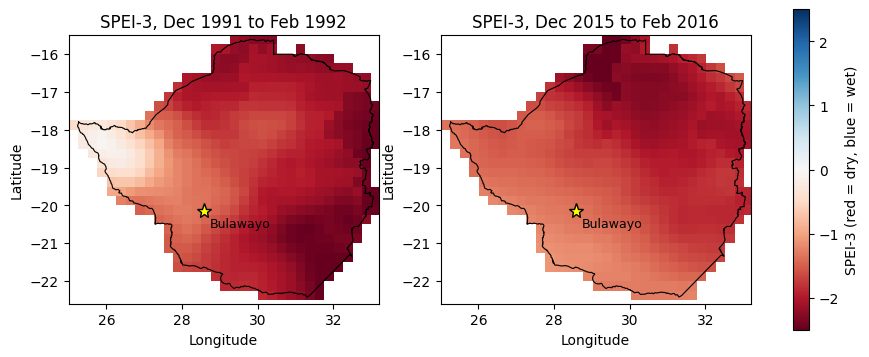

In [14]:
LON0, LON1, LAT0, LAT1 = 25.0, 33.25, -15.5, -22.75   # grid edges (0.25 degree cells), LAT0 is the top

def spei_map(end_month, k, y0=1981, y1=2024):
    proj = tc.first().projection()
    D = tc.map(lambda im: im.select('pr')
               .subtract(im.select('pet').multiply(PET_SCALE)).rename('D')
               .copyProperties(im, ['system:time_start']))
    years, imgs = [], []
    for y in range(y0, y1 + 1):
        start = pd.Timestamp(y, end_month, 1) - pd.DateOffset(months=k - 1)
        if start < pd.Timestamp(START):
            continue                      # window would start before the data begins
        e = ee.Date.fromYMD(y, end_month, 1).advance(1, 'month')
        imgs.append(D.filterDate(e.advance(-k, 'month'), e).sum().rename(f'y{y}'))
        years.append(y)
    mask = ee.Image.constant(1).clip(ZIMBABWE).unmask(0).rename('mask')
    stack = (ee.Image.cat(imgs + [mask]).setDefaultProjection(proj)
             .reduceResolution(ee.Reducer.mean(), maxPixels=256)
             .reproject(crs='EPSG:4326', crsTransform=[0.25, 0, LON0, 0, -0.25, LAT0]))
    region = ee.Geometry.Rectangle([LON0, LAT1, LON1, LAT0], 'EPSG:4326', False)
    props = stack.sampleRectangle(region=region, defaultValue=0).getInfo()['properties']

    arr = np.stack([np.array(props[f'y{y}'], float) for y in years])      # (years, rows, cols)
    arr[arr == -9999] = np.nan
    inside = np.array(props['mask'], float) > 0.5
    z = np.full_like(arr, np.nan)
    for r in range(arr.shape[1]):
        for c in range(arr.shape[2]):
            if not inside[r, c] or np.isnan(arr[:, r, c]).any():
                continue
            x = arr[:, r, c]
            p = fit_loglogistic(x)
            if p is not None:
                z[:, r, c] = to_z(loglogistic_cdf(x, p))
            else:                         # fallback: normal distribution
                z[:, r, c] = to_z(stats.norm.cdf(x, loc=x.mean(), scale=x.std(ddof=1)))
    return dict(zip(years, z))

def border_lines():
    g = ZIMBABWE.getInfo()
    polys = [g['coordinates']] if g['type'] == 'Polygon' else g['coordinates']
    return [np.array(poly[0]) for poly in polys]

maps = spei_map(end_month=2, k=3)
borders = border_lines()

events = [1992, 2016]
fig, axes = plt.subplots(1, len(events), figsize=(11, 5.2))
for ax, yr in zip(np.atleast_1d(axes), events):
    im = ax.imshow(maps[yr], extent=[LON0, LON1, LAT1, LAT0], cmap='RdBu', vmin=-2.5, vmax=2.5)
    for b in borders:
        ax.plot(b[:, 0], b[:, 1], 'k', lw=0.8)
    ax.plot(28.58, -20.15, 'k*', ms=11, mfc='yellow')
    ax.annotate('Bulawayo', (28.58, -20.15), xytext=(4, -12), textcoords='offset points', fontsize=9)
    ax.set_xlim(25.0, 33.2); ax.set_ylim(-22.6, -15.5)
    ax.set_title(f'SPEI-3, Dec {yr-1} to Feb {yr}')
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
fig.colorbar(im, ax=axes, shrink=0.8, label='SPEI-3 (red = dry, blue = wet)')
plt.savefig('fig4_spei3_maps.png', dpi=200, bbox_inches='tight')
plt.show()

## 12. Save results and download
Saves the monthly tables (temperature, both PET methods, D, all indices) as CSV files and bundles them with the four figures into one zip.

In [15]:
import zipfile, glob
for name, d in res.items():
    d.to_csv(f'spei_{name.lower()}_monthly.csv')
with zipfile.ZipFile('spei_outputs.zip', 'w') as z:
    for f in glob.glob('fig*.png') + glob.glob('spei_*_monthly.csv'):
        z.write(f)
try:
    from google.colab import files
    files.download('spei_outputs.zip')
except ImportError:
    print('Not in Colab: files are saved in the working directory.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What to say about the script (for your presentation)
1. **Inputs:** monthly precipitation (TerraClimate) and air temperature (ERA5-Land), averaged over Zimbabwe and a 10 km circle around Bulawayo.
2. **PET:** calculated in the notebook with the Thornthwaite method from temperature (the main method), and compared with TerraClimate's FAO Penman-Monteith PET.
3. **Water balance:** `D = P - PET` per month, then summed over 1, 3, 6 and 12 month windows.
4. **Standardization:** for each calendar month, a log-logistic distribution is fitted to D, turned into a probability, then into a z-score. That is the SPEI.
5. **Comparison:** the same is done with rainfall only (Gamma distribution) to get SPI, to show the effect of temperature/PET.
6. **Temperature effect:** trends in temperature and PET, SPEI minus SPI in dry months, a regression on temperature anomaly, and drought frequency by period.
7. **Outputs:** SPEI time series, SPEI vs SPI figure, temperature-effect figure, and spatial maps for two historic drought seasons.
8. **Limitations:** Thornthwaite uses temperature only and is known to react more strongly to warming than Penman-Monteith; the two methods are compared for that reason.
   The map resolution is coarse (0.25 degree), and SPEI describes dryness relative to 1981-2024, not absolute water availability.

## 13. Results and interpretation

**What the historical observations show (1981–2024).** The national mean annual precipitation was **636 mm**, compared with **572 mm** in the 10 km Bulawayo case-study buffer. The strongest national Thornthwaite-based **SPEI-12** in the saved series was **−2.43 in February 2016**, while Bulawayo reached **−2.39 in March 2024**. The notebook also identifies the 1992 national drought (minimum annual SPEI-12 of **−2.22**).

**Why the PET method matters.** The Thornthwaite annual PET averages were **1,021 mm (Zimbabwe)** and **891 mm (Bulawayo)**, compared with Penman–Monteith estimates of **1,581** and **1,607 mm**. At the 12-month scale, the national share of months with index `< −1` was **18% for SPI**, **16% for Thornthwaite SPEI**, and **17% for Penman–Monteith SPEI**. Bulawayo's corresponding shares were **13%**, **17%**, and **16%**. Accounting for PET changes the drought assessment but does **not** automatically make SPEI more negative.

**Warming and evaporative-demand relationships.** The estimated annual temperature trends were **+0.13 °C/decade** nationally (`p = 0.054`) and **+0.12 °C/decade** in Bulawayo (`p = 0.114`); neither passes the conventional 5% significance threshold. The regressions relating the 3-month temperature anomaly to **SPEI-3 minus SPI-3** were negative for both locations (Thornthwaite slopes **−0.41** and **−0.35 index units/°C**, respectively; both printed `p = 0.000`, meaning **p < 0.001** at the shown precision). Warmer-than-normal periods therefore *tended* to make SPEI relatively lower than SPI. This is an **association**, not independent causal attribution, in part because temperature enters the PET calculation.

**An important counterexample to a simple narrative.** During dry months defined by `SPI-3 < −1`, the **average** difference `SPEI-3 − SPI-3` was **+0.35 for Zimbabwe** and **+0.23 for Bulawayo** with Thornthwaite PET. The evidence does **not** show that PET increases drought severity in every event or calendar period. In **2011–2024**, however, Bulawayo's share of dry months was **12% by SPI-3** versus **27% by Thornthwaite SPEI-3**, making local differences especially important to investigate.

**Conclusion.** The analysis identifies major drought episodes and shows that regional scale, index selection, and PET estimation meaningfully influence drought monitoring. The strongest defensible conclusion is that incorporating evaporative demand **adds useful information to rainfall-only drought assessments**, rather than that temperature changes caused every major drought in the historical record.

**Further limitations:** The Bulawayo buffer is not an administrative boundary; gridded maps use a coarse 0.25° resolution; national Thornthwaite uses an approximate fixed latitude; and regression p-values do not explicitly adjust for serial correlation. See the repository README for additional methodological context.
